# Практическое занятие № 14 — TimeSeriesSplit, Pipeline, GridSearchCV
**ТюмГУ · Технологии искусственного интеллекта — 1 · 90 минут**

**Цель:** подобрать гиперпараметры регрессионной модели при хронологическом порядке данных, избежать утечек в cross-validation, сравнить CV с holdout и **один раз** проверить финальную модель на test.

**Важно:** `late` и `actual_minutes` нельзя использовать как входы; `actual_minutes` здесь — целевая переменная. `test` не участвует в обучении, подборе, нормировке или выборе между гипотезами.

## 1. Аудит данных и повторение пайплайна (0–17 мин)
Повторяем ту же политику подготовки и то же хронологическое разбиение, что на занятии 13. Проверяем непересечение ID. Изменение правил после изучения теста запрещено.

In [1]:
# ОБЩАЯ ПОДГОТОВКА: выполняется самостоятельно в каждом блокноте.
# В Colab загрузите orders_dirty.csv через боковую панель «Файлы».
# При отсутствии официального файла используйте только demo_orders_13_14.csv
# и ОТМЕТЬТЕ В ОТЧЁТЕ, что результаты демонстрационные.
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

DATA_PATH = Path('orders_dirty.csv')
if not DATA_PATH.exists():
    DATA_PATH = Path('demo_orders_13_14.csv')
if not DATA_PATH.exists():
    raise FileNotFoundError('Загрузите orders_dirty.csv (учебный источник) либо demo_orders_13_14.csv (только демонстрация).')
source_type = 'ОФИЦИАЛЬНЫЙ/УЧЕБНЫЙ НАБОР' if DATA_PATH.name=='orders_dirty.csv' else 'ДЕМОНСТРАЦИОННЫЕ ДАННЫЕ — НЕ СДАВАТЬ КАК ОСНОВНОЙ ИСТОЧНИК'
print('Источник:', DATA_PATH.name, '|', source_type)
raw = pd.read_csv(DATA_PATH, encoding='utf-8-sig')
REQUIRED = {'order_id','created_at','distance_km','queue_size','promised_minutes','zone','weather','actual_minutes','late'}
assert REQUIRED.issubset(raw.columns), f'Отсутствуют поля: {sorted(REQUIRED-set(raw.columns))}'
print('Исходный размер:', raw.shape, 'Полных повторов:', int(raw.duplicated().sum()))
print('Типы исходных столбцов:')
print(raw.dtypes.to_string())
if 'courier_load' not in raw.columns:
    raw['courier_load']=np.nan
    print('courier_load отсутствует в источнике; в рабочей копии создан только пустой столбец.')

# Для регрессии actual_minutes — цель; late запрещено использовать как признак.
# Пустой/нечисловой target не подходит для fit и оценки; диапазон 5–240 —
# учебное правило качества, согласованное со словарём данных, а не физический закон.
df=raw.drop_duplicates().copy()
df['created_at']=pd.to_datetime(df['created_at'], errors='coerce')
df['actual_minutes']=pd.to_numeric(df['actual_minutes'], errors='coerce')
missing_target=df['actual_minutes'].isna()
out_of_range=df['actual_minutes'].notna() & ~df['actual_minutes'].between(5,240,inclusive='both')
print('Пропущенная/нечисловая цель:',int(missing_target.sum()),
      'вне учебного диапазона 5–240:',int(out_of_range.sum()))
valid_target=df['actual_minutes'].between(5,240,inclusive='both')
valid_time=df['created_at'].notna()
valid_id=df['order_id'].notna()
print('Цель вне 5–240 или NaN:',int((~valid_target).sum()),
      'невалидных дат:',int((~valid_time).sum()),'пустых ID:',int((~valid_id).sum()))
df=df.loc[valid_target & valid_time & valid_id].copy()
# Если разные строки имеют один ID, студент обязан разобраться с ним до разбиения.
assert df['order_id'].is_unique, 'Конфликтующие order_id: разберите вручную до продолжения.'
df=df.sort_values(['created_at','order_id'],kind='stable').reset_index(drop=True)
assert len(df)>=45, f'Для этой демонстрации нужно хотя бы 45 валидных заказов, найдено {len(df)}'
n=len(df)
n_train=int(n*.6); n_dev=int(n*.8)
train=df.iloc[:n_train].copy(); val=df.iloc[n_train:n_dev].copy(); test=df.iloc[n_dev:].copy()
assert len(train)>0 and len(val)>0 and len(test)>0
assert set(train['order_id']).isdisjoint(val['order_id'])
assert set(train['order_id']).isdisjoint(test['order_id'])
assert set(val['order_id']).isdisjoint(test['order_id'])
assert train['created_at'].max()<=val['created_at'].min()<=test['created_at'].min()
print('После очистки:',n,'train/val/test:',list(map(len,[train,val,test])))
print('Доли частей:',[round(len(part)/n,4) for part in (train,val,test)])
print('Общих order_id между частями: 0; сумма размеров:',len(train)+len(val)+len(test))
print('Временные границы непрерывны по сортировке; разрывы между частями:',
      val.created_at.min()-train.created_at.max(),
      test.created_at.min()-val.created_at.max())
print('Временные диапазоны:')
for name,part in [('train',train),('val',val),('test (метрики только после выбора модели)',test)]:
    print(name, len(part),str(part.created_at.min()),'…',str(part.created_at.max()))

NUM_BASE=['distance_km','queue_size','courier_load','promised_minutes']
CAT=['zone','weather']
DERIVED=['hour_sin','hour_cos','planned_speed_kmh']
NUM=NUM_BASE+DERIVED
INPUT=NUM_BASE+CAT+['created_at']

def make_features(X):
    # Функция НЕ обучается по данным и применяется идентично внутри каждого fold.
    f=X.loc[:,INPUT].copy()
    for k in NUM_BASE:
        f[k]=pd.to_numeric(f[k], errors='coerce')
        f.loc[f[k]<0,k]=np.nan
    f.loc[f['promised_minutes']<=0,'promised_minutes']=np.nan
    for k in CAT:
        s=f[k].astype('string').str.strip()
        s=s.mask(s.str.lower().isin(['','nan','none','null','нет данных','неизвестно']))
        f[k]=s.astype(object).where(s.notna(),np.nan)
    ts=pd.to_datetime(f['created_at'],errors='coerce')
    hour=ts.dt.hour.astype(float)
    f['hour_sin']=np.sin(2*np.pi*hour/24)
    f['hour_cos']=np.cos(2*np.pi*hour/24)
    f['planned_speed_kmh']=60*f['distance_km']/f['promised_minutes']
    f['planned_speed_kmh']=f['planned_speed_kmh'].replace([np.inf,-np.inf],np.nan)
    return f.drop(columns=['created_at'])

num_pipe=Pipeline([('impute',SimpleImputer(strategy='median',add_indicator=True,keep_empty_features=True)),('scale',StandardScaler())])
cat_pipe=Pipeline([('impute',SimpleImputer(strategy='constant',fill_value='неизвестно')),
                   ('onehot',OneHotEncoder(handle_unknown='ignore',sparse_output=False))])
prep=ColumnTransformer([('num',num_pipe,NUM),('cat',cat_pipe,CAT)],remainder='drop')

def build_pipeline(regressor):
    return Pipeline([('derive',FunctionTransformer(make_features,validate=False)),
                     ('prep',clone(prep)),('model',regressor)])

def eval_regression(y_true,y_pred):
    return {'MAE':float(mean_absolute_error(y_true,y_pred)),
            'RMSE':float(np.sqrt(mean_squared_error(y_true,y_pred))),
            'R2':float(r2_score(y_true,y_pred))}
Xtrain=train[INPUT].copy(); ytrain=train['actual_minutes'].copy()
Xval=val[INPUT].copy(); yval=val['actual_minutes'].copy()
# test хранится отдельно; целевая переменная и метрики не открываются до финальной ячейки.
assert {'order_id','late','actual_minutes'}.isdisjoint(Xtrain.columns)
print('Входные поля:',INPUT,'Цель: actual_minutes (мин)')
print('Признаков до кодирования:',len(NUM)+len(CAT),'; test-цель и test-метрики не просматривались.')


Источник: orders_dirty.csv | ОФИЦИАЛЬНЫЙ/УЧЕБНЫЙ НАБОР
Исходный размер: (600, 10) Полных повторов: 1
Типы исходных столбцов:
order_id             object
created_at           object
distance_km          object
queue_size          float64
weather              object
zone                 object
promised_minutes      int64
actual_minutes        int64
late                  int64
vehicle_type         object
courier_load отсутствует в источнике; в рабочей копии создан только пустой столбец.
Пропущенная/нечисловая цель: 0 вне учебного диапазона 5–240: 0
Цель вне 5–240 или NaN: 0 невалидных дат: 0 пустых ID: 0
После очистки: 599 train/val/test: [359, 120, 120]
Доли частей: [0.5993, 0.2003, 0.2003]
Общих order_id между частями: 0; сумма размеров: 599
Временные границы непрерывны по сортировке; разрывы между частями: 0 days 00:51:00 0 days 01:57:00
Временные диапазоны:
train 359 2026-08-25 08:00:00 … 2026-09-28 02:45:00
val 120 2026-09-28 03:36:00 … 2026-10-06 02:42:00
test (метрики только после 

## 2. Как устроен TimeSeriesSplit (17–33 мин)

Каждая проверочная часть расположена **позже** обучающей. Размер обучающей части увеличивается по мере перехода от фолда к фолду. Это не означает автоматической защиты от всех временных утечек: признаки должны быть доступны на момент предсказания, а связанные наблюдения не должны пересекать границу train/val.

Для демонстрации используйте `n_splits=4`, `gap=0` (нет дополнительных задержек обновления данных); обоснуйте, когда нужен `gap>0`.

In [2]:
from sklearn.model_selection import GridSearchCV
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor

# Разработка: только первые 80% времени (train+val). Test=последние 20%.
dev=pd.concat([train,val],axis=0).sort_values(['created_at','order_id'],kind='stable').reset_index(drop=True)
Xdev=dev[INPUT].copy(); ydev=dev['actual_minutes'].copy()
cv=TimeSeriesSplit(n_splits=4)
fold_table=[]
for i,(tr_idx,v_idx) in enumerate(cv.split(Xdev),1):
    fold_table.append({'fold':i,'train_n':len(tr_idx),'val_n':len(v_idx),
        'train_min':str(dev.iloc[tr_idx].created_at.min()),
        'train_max':str(dev.iloc[tr_idx].created_at.max()),
        'val_min':str(dev.iloc[v_idx].created_at.min()),
        'val_max':str(dev.iloc[v_idx].created_at.max()),
        'chronology_ok':bool(dev.iloc[tr_idx].created_at.max()<=dev.iloc[v_idx].created_at.min())})
folds=pd.DataFrame(fold_table)
display(folds)
assert folds['chronology_ok'].all()
assert len(dev)==int(len(df)*.8)==len(train)+len(val)
assert set(dev['order_id']).isdisjoint(test['order_id'])
print('gap=0: в этом учебном наборе нет заданной задержки появления данных;')
print('при такой задержке gap должен исключать соответствующее число ближайших наблюдений.')
folds.to_csv('14_timeseries_folds.csv',index=False,encoding='utf-8-sig')

,fold,train_n,val_n,train_min,train_max,val_min,val_max,chronology_ok
0,1,99,95,2026-08-25 08:00:00,2026-09-10 18:18:00,2026-09-10 20:15:00,2026-09-17 02:24:00,True
1,2,194,95,2026-08-25 08:00:00,2026-09-17 02:24:00,2026-09-17 04:21:00,2026-09-23 10:30:00,True
2,3,289,95,2026-08-25 08:00:00,2026-09-23 10:30:00,2026-09-23 12:27:00,2026-09-29 18:36:00,True
3,4,384,95,2026-08-25 08:00:00,2026-09-29 18:36:00,2026-09-29 20:33:00,2026-10-06 02:42:00,True


gap=0: в этом учебном наборе нет заданной задержки появления данных;
при такой задержке gap должен исключать соответствующее число ближайших наблюдений.


## 3. Систематический подбор гиперпараметров (33–63 мин)

Ищем конфигурацию с минимальной средней MAE по временным фолдам. В scikit-learn отрицательный `neg_mean_absolute_error` используется потому, что GridSearchCV **максимизирует** оценку. Пишем результат обратно в минутах: `CV_MAE = −mean_test_score`.

На каждом фолде `Pipeline` заново обучает SimpleImputer, StandardScaler, OneHotEncoder и регрессор **только на доступной тренировочной части**.

In [3]:
searches={
 'Ridge':(
   build_pipeline(Ridge()), {'model__alpha':[0.1,1.0,10.0,100.0]}
 ),
 'RandomForest':(
   build_pipeline(RandomForestRegressor(n_estimators=100,random_state=42,n_jobs=-1)),
   {'model__max_depth':[4,8,None], 'model__min_samples_leaf':[2,5]}
 )
}
cv_results=[]; grid_models={}
for name,(pipe,grid) in searches.items():
    gs=GridSearchCV(estimator=pipe,param_grid=grid,scoring='neg_mean_absolute_error',
                    cv=cv,refit=True,n_jobs=1,return_train_score=True,error_score='raise')
    gs.fit(Xdev,ydev)
    grid_models[name]=gs
    cv_results.append({'model':name,'CV_MAE':-float(gs.best_score_),
                       'best_params':str(gs.best_params_)})
    print(name,'MAE CV:',round(-gs.best_score_,3),'параметры:',gs.best_params_)
results_cv=pd.DataFrame(cv_results).sort_values(['CV_MAE','model']).reset_index(drop=True)
display(results_cv)
results_cv.to_csv('14_cv_summary.csv',index=False,encoding='utf-8-sig')
for name,gs in grid_models.items():
    pd.DataFrame(gs.cv_results_).to_csv(f'14_cv_grid_{name}.csv',index=False,encoding='utf-8-sig')
all_candidates=[]
for name,gs in grid_models.items():
    for j,param in enumerate(gs.cv_results_['params']):
        entry={'model':name,'params':str(param),
               'CV_MAE':-float(gs.cv_results_['mean_test_score'][j])}
        for k in range(4):
            entry[f'fold_{k+1}_MAE']=-float(gs.cv_results_[f'split{k}_test_score'][j])
        all_candidates.append(entry)
candidate_table=pd.DataFrame(all_candidates).sort_values(['CV_MAE','model','params']).reset_index(drop=True)
print('Две лучшие конфигурации всей сетки:')
display(candidate_table.head(2).round(3))
candidate_table.to_csv('14_cv_all_candidates.csv',index=False,encoding='utf-8-sig')
assert len(candidate_table)==10


Ridge MAE CV: 8.255 параметры: {'model__alpha': 1.0}
RandomForest MAE CV: 8.585 параметры: {'model__max_depth': 4, 'model__min_samples_leaf': 5}


,model,CV_MAE,best_params
0,Ridge,8.254527,{'model__alpha': 1.0}
1,RandomForest,8.585260,"{'model__max_depth': 4, 'model__min_samples_le..."


Две лучшие конфигурации всей сетки:


,model,params,CV_MAE,fold_1_MAE,fold_2_MAE,fold_3_MAE,fold_4_MAE
0,Ridge,{'model__alpha': 1.0},8.255,7.475,8.656,8.531,8.356
1,Ridge,{'model__alpha': 10.0},8.263,7.516,8.757,8.556,8.222


## 4. Проверка устойчивости и визуализация (63–77 мин)

Посмотрите, в каких фолдах ошибки существенно различаются. Если качество меняется от периода к периоду, один средний показатель скрывает нестабильность. Зафиксируйте выбранный алгоритм и его параметры **до тестирования**.

Ridge MAE по фолдам: [7.475, 8.656, 8.531, 8.356] размах: 1.181 мин; последний фолд: 8.356
RandomForest MAE по фолдам: [8.332, 8.336, 9.341, 8.332] размах: 1.01 мин; последний фолд: 8.332


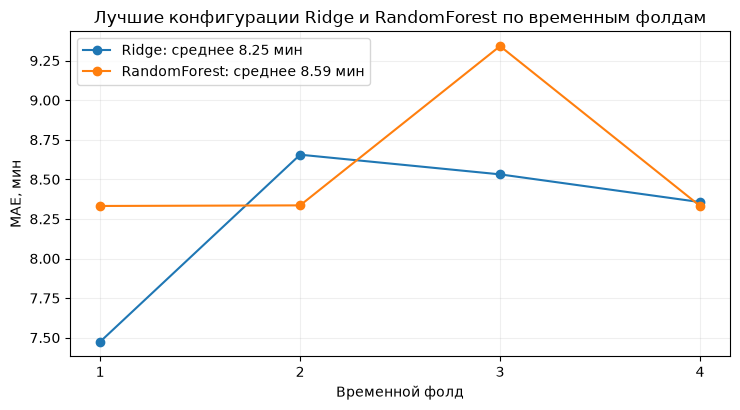

Победитель по минимальной средней CV_MAE: Ridge 8.255 мин; различие фолдов требует осторожности.
Решение зафиксировано до использования test: {'selected_model': 'Ridge', 'selected_hyperparameters': {'model__alpha': 1.0}, 'selection_metric': 'TimeSeriesSplit(n_splits=4), mean MAE (minutes)', 'cv_mae_minutes': 8.254527411863766, 'train_dev_n': 479, 'test_n': 120, 'data_source': 'orders_dirty.csv', 'random_state': 42, 'test_status': 'контрольная учебная оценка: часть того же корпуса ранее анализировалась в работах 10–12'}


In [4]:
winner=str(results_cv.iloc[0]['model'])
best_grid=grid_models[winner]
fold_scores={}
fig,ax=plt.subplots(figsize=(7.5,4.2))
for name,gs in grid_models.items():
    row=gs.best_index_
    values=[-float(gs.cv_results_[f'split{i}_test_score'][row]) for i in range(4)]
    fold_scores[name]=values
    ax.plot(range(1,5),values,marker='o',label=f'{name}: среднее {np.mean(values):.2f} мин')
    print(name,'MAE по фолдам:',[round(v,3) for v in values],
          'размах:',round(max(values)-min(values),3),'мин; последний фолд:',round(values[-1],3))
ax.set(xticks=[1,2,3,4],xlabel='Временной фолд',ylabel='MAE, мин',
       title='Лучшие конфигурации Ridge и RandomForest по временным фолдам')
ax.grid(alpha=.2);ax.legend();fig.tight_layout()
fig.savefig('14_mae_by_fold.png',dpi=160);plt.show()
print('Победитель по минимальной средней CV_MAE:',winner,
      round(float(-best_grid.best_score_),3),'мин; различие фолдов требует осторожности.')

from pathlib import Path
import json
config={'selected_model':winner,'selected_hyperparameters':best_grid.best_params_,
       'selection_metric':'TimeSeriesSplit(n_splits=4), mean MAE (minutes)',
       'cv_mae_minutes':float(-best_grid.best_score_),
       'train_dev_n':int(len(dev)),'test_n':int(len(test)),
       'data_source':DATA_PATH.name,'random_state':42,
       'test_status':'контрольная учебная оценка: часть того же корпуса ранее анализировалась в работах 10–12'}
Path('14_selected_config.json').write_text(json.dumps(config,ensure_ascii=False,indent=2),encoding='utf-8')
print('Решение зафиксировано до использования test:',config)

## 5. Один финальный тест и ограничения (77–90 мин)

ВНИМАНИЕ: финальный тест проводим **только после записи** `14_selected_config.json`. В этом учебном проекте тестовые заказы могли уже анализироваться в других практиках; поэтому статистику нельзя безоговорочно считать независимой внешней валидацией. Для производственной системы нужен новый будущий период.

После теста не изменяйте гиперпараметры по его результату.

Зафиксированная модель: Ridge
Тестовые метрики: {'MAE': 8.441, 'RMSE': 10.195, 'R2': 0.817}


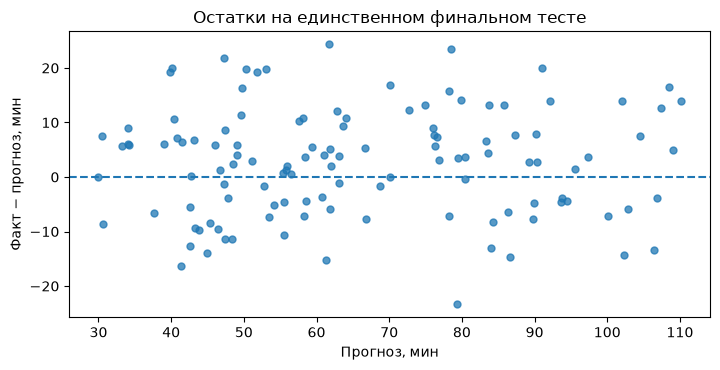

Сравнение с CV: MAE(test) − CV_MAE = 0.187 мин.
Test оценён один раз после записи JSON; дальнейший выбор по нему не выполняется.


In [5]:
# Единственная ячейка, обращающаяся к test для оценки модели.
assert Path('14_selected_config.json').exists(), 'Сначала зафиксируйте конфигурацию.'
Xtest=test[INPUT].copy(); ytest=test['actual_minutes'].copy()
assert {'order_id','late','actual_minutes'}.isdisjoint(Xtest.columns)
final_model=best_grid.best_estimator_  # refit=True уже обучил на dev
pred_test=final_model.predict(Xtest)
metrics_test=eval_regression(ytest,pred_test)
print('Зафиксированная модель:',winner)
print('Тестовые метрики:',{k:round(v,3) for k,v in metrics_test.items()})
pd.DataFrame([{'selected_model':winner,'dev_n':len(dev),'test_n':len(test),
              **metrics_test}]).to_csv('14_final_test_metrics.csv',index=False,encoding='utf-8-sig')
pd.DataFrame({'order_id':test['order_id'].values,'actual_minutes':ytest.values,
              'predicted_minutes':pred_test,
              'residual_minutes':ytest.values-pred_test}).to_csv('14_final_test_predictions.csv',index=False,encoding='utf-8-sig')
fig,ax=plt.subplots(figsize=(7.3,3.8))
ax.scatter(pred_test,ytest.values-pred_test,alpha=.75,s=25)
ax.axhline(0,ls='--');ax.set(xlabel='Прогноз, мин',ylabel='Факт − прогноз, мин',title='Остатки на единственном финальном тесте')
fig.tight_layout();fig.savefig('14_final_residuals.png',dpi=160);plt.show()
print('Сравнение с CV: MAE(test) − CV_MAE =',
      round(metrics_test['MAE']-float(-best_grid.best_score_),3),'мин.')
print('Test оценён один раз после записи JSON; дальнейший выбор по нему не выполняется.')


## 6. Самостоятельная работа и сдача

1. Сравните два лучших набора гиперпараметров; объясните свой выбор по CV_MAE и вариации между фолдами.
2. Для одного фолда укажите максимальную дату обучения и минимальную дату проверки; обоснуйте необходимость `gap`, если данные поступают с задержкой.
3. Объясните, почему `SimpleImputer.fit` до разбиения на фолды создаёт утечку.
4. Приведите **один** финальный тест и отличия от CV. Если ранее test использовался для корректировки модели, явно отметьте это ограничение.
5. Укажите, как вы организовали бы честную проверку на новом месяце заказов.

**Сдать:** `Группа_Фамилия_З14_Отчёт.docx` (или PDF), `14_student.ipynb`, `14_selected_config.json`, CSV с CV и тестом, два PNG. Объём 3–5 страниц без приложений. В Colab запустите «Среда выполнения → Выполнить все» после сброса состояния.

**Ответы на самостоятельные задания.**

1. Две лучшие конфигурации всей сетки — Ridge с `alpha=1` (CV MAE 8,255 мин; по фолдам 7,475; 8,656; 8,531; 8,356) и Ridge с `alpha=10` (8,263 мин; 7,516; 8,757; 8,556; 8,222). Разница средних всего 0,008 мин, поэтому нельзя говорить о доказанном преимуществе. По заранее заданному минимуму CV MAE выбран `alpha=1`. Лучший Forest (`max_depth=4`, `min_samples_leaf=5`) дал 8,585 мин; его результат на последнем фолде 8,332 мин сам по себе не меняет критерий выбора.
2. В первом фолде train заканчивается 10.09.2026 18:18, validation начинается 10.09.2026 20:15; train содержит 99, validation — 95 заказов. `gap=0` принят потому, что в кейсе не задана задержка появления признаков. Если обновления очереди или загрузки курьеров поступают с задержкой, из конца train нужно исключить соответствующее число наблюдений; длину gap выводят из этой задержки и частоты заказов, а не подбирают по test.
3. `SimpleImputer.fit` на всём dev до разбиения на фолды использовал бы будущие значения для медианы и сведения о будущих пропусках. Тогда проверочная часть влияла бы на преобразование train. В едином Pipeline импутер, масштабирование и OHE переобучаются отдельно на train каждого фолда.
4. После фиксации Ridge (`alpha=1`) и JSON выполнен один test на 120 заказах: MAE 8,441 мин, RMSE 10,195 мин, R² 0,817. CV MAE была 8,255 мин, то есть тестовая MAE выше на 0,187 мин. Это другая временная часть, а не дополнительный фолд для подбора. Из 120 её заказов 22 входили в ранее просмотренный случайный test работ 10–12; результат учебный и не полностью независимый. После теста параметры не менялись.
5. Для честной проверки на новом месяце я бы заранее зафиксировал источник данных, схему признаков, очистку, Pipeline, параметры Ridge и метрики. Затем собрал бы все заказы следующего месяца, не использованные в выборе, и один раз оценил бы MAE, RMSE, R² и остатки; любые новые изменения модели проверял бы уже на следующем отдельном периоде.